In [1]:
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

DATA_DIR = Path(".")  # Change this if your CSV files are in another folder
pd.set_option("display.max_columns", 100)
pd.set_option("display.width", 140)
sns.set_theme()  # Default Seaborn theme; charts are exploratory


## 2. Load the five CSV files

In [2]:
bookings_raw = pd.read_csv(DATA_DIR / "bookings.csv")
movies_raw = pd.read_csv(DATA_DIR / "movies.csv")
cinemas_raw = pd.read_csv(DATA_DIR / "cinemas.csv")
pricing_raw = pd.read_csv(DATA_DIR / "pricing.csv")
calendar_raw = pd.read_csv(DATA_DIR / "calendar.csv")

datasets = {
    "bookings": bookings_raw,
    "movies": movies_raw,
    "cinemas": cinemas_raw,
    "pricing": pricing_raw,
    "calendar": calendar_raw,
}
for name, df in datasets.items():
    print(f"\\n{name}: shape={df.shape}")
    display(df.head())


\nbookings: shape=(1252, 11)


,booking_id,show_id,date,cinema,screen,movie,show_time,seat_class,offer,tickets,revenue
0,100001,500001,2026-01-01,SS_Coimbatore,2,Shadow Case,13:00,Standard,Student 20%,63,6048
1,100002,500002,2026-01-01,SS_Coimbatore,2,Galactic Run,16:00,Standard,No Offer,52,7800
2,100003,500003,2026-01-01,SS_Coimbatore,2,Hearts of Chennai,22:00,Premium,Student 20%,25,4400
3,100004,500004,2026-01-01,SS_Tiruppur,1,Forest Guardians,10:00,Premium,No Offer,62,13640
4,100005,500005,2026-01-01,SS_Tiruppur,1,The Last Fortress,13:00,Standard,Student 20%,33,3168


\nmovies: shape=(7, 5)


,movie,genre,language,runtime,certification
0,Galactic Run,Sci-Fi,English,142,UA
1,Hearts of Chennai,Romance,Tamil,128,U
2,The Last Fortress,Action,English,135,UA
3,Laugh Track,Comedy,Tamil,116,U
4,Forest Guardians,Adventure,Tamil,124,U


\ncinemas: shape=(4, 4)


,cinema,city,screen,screen_capacity
0,SS_Coimbatore,Coimbatore,1,120
1,SS_Coimbatore,Coimbatore,2,90
2,SS_Tiruppur,Tiruppur,1,100
3,SS_Erode,Erode,1,80


\npricing: shape=(6, 3)


,seat_class,ticket_price,offer
0,Standard,150,No Offer
1,Standard,120,Student 20%
2,Premium,220,No Offer
3,Premium,187,Student 15%
4,Recliner,320,No Offer


\ncalendar: shape=(90, 4)


,date,weekday,holiday,release_week
0,2026-01-01,Thursday,True,1
1,2026-01-02,Friday,False,1
2,2026-01-03,Saturday,False,1
3,2026-01-04,Sunday,False,1
4,2026-01-05,Monday,False,1


## 3. Inspect schema and quality

In [3]:
for name, df in datasets.items():
    print(f"\\n--- {name.upper()} ---")
    df.info()
    display(df.isna().sum().rename("missing_count").to_frame())
    print("Exact duplicate rows:", int(df.duplicated().sum()))


\n--- BOOKINGS ---
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1252 entries, 0 to 1251
Data columns (total 11 columns):
 #   Column      Non-Null Count  Dtype 
---  ------      --------------  ----- 
 0   booking_id  1252 non-null   int64 
 1   show_id     1252 non-null   int64 
 2   date        1252 non-null   object
 3   cinema      1252 non-null   object
 4   screen      1252 non-null   int64 
 5   movie       1252 non-null   object
 6   show_time   1251 non-null   object
 7   seat_class  1252 non-null   object
 8   offer       1252 non-null   object
 9   tickets     1252 non-null   int64 
 10  revenue     1252 non-null   int64 
dtypes: int64(5), object(6)
memory usage: 107.7+ KB


,missing_count
booking_id,0
show_id,0
date,0
cinema,0
screen,0
movie,0
show_time,1
seat_class,0
offer,0
tickets,0


Exact duplicate rows: 1
\n--- MOVIES ---
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 7 entries, 0 to 6
Data columns (total 5 columns):
 #   Column         Non-Null Count  Dtype 
---  ------         --------------  ----- 
 0   movie          7 non-null      object
 1   genre          7 non-null      object
 2   language       7 non-null      object
 3   runtime        7 non-null      int64 
 4   certification  7 non-null      object
dtypes: int64(1), object(4)
memory usage: 412.0+ bytes


,missing_count
movie,0
genre,0
language,0
runtime,0
certification,0


Exact duplicate rows: 0
\n--- CINEMAS ---
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 4 entries, 0 to 3
Data columns (total 4 columns):
 #   Column           Non-Null Count  Dtype 
---  ------           --------------  ----- 
 0   cinema           4 non-null      object
 1   city             4 non-null      object
 2   screen           4 non-null      int64 
 3   screen_capacity  4 non-null      int64 
dtypes: int64(2), object(2)
memory usage: 260.0+ bytes


...

Exact duplicate rows: 0
\n--- PRICING ---
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 6 entries, 0 to 5
Data columns (total 3 columns):
 #   Column        Non-Null Count  Dtype 
---  ------        --------------  ----- 
 0   seat_class    6 non-null      object
 1   ticket_price  6 non-null      int64 
 2   offer         6 non-null      object
dtypes: int64(1), object(2)
memory usage: 276.0+ bytes


,missing_count
seat_class,0
ticket_price,0
offer,0


Exact duplicate rows: 0
\n--- CALENDAR ---
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 90 entries, 0 to 89
Data columns (total 4 columns):
 #   Column        Non-Null Count  Dtype 
---  ------        --------------  ----- 
 0   date          90 non-null     object
 1   weekday       90 non-null     object
 2   holiday       90 non-null     bool  
 3   release_week  90 non-null     int64 
dtypes: bool(1), int64(1), object(2)
memory usage: 2.3+ KB


,missing_count
date,0
weekday,0
holiday,0
release_week,0


Exact duplicate rows: 0


In [4]:
# Inspect key uniqueness before merging
print("Cinema/screen capacity key duplicates:",
      int(cinemas_raw.duplicated(["cinema", "screen"]).sum()))
print("Pricing key duplicates:",
      int(pricing_raw.duplicated(["seat_class", "offer"]).sum()))
print("Movie names:", sorted(movies_raw["movie"].dropna().unique()))
print("Genre labels:", sorted(movies_raw["genre"].dropna().astype(str).unique()))


Cinema/screen capacity key duplicates: 0
Pricing key duplicates: 0
Movie names: ['Forest Guardians', 'Galactic Run', 'Hearts of Chennai', 'Laugh Track', 'Shadow Case', 'The Last Fortress']
Genre labels: ['Action', 'Adventure', 'Comedy', 'Romance', 'Sci-Fi', 'Thriller', 'sci fi']


## 4. Clean each dataset

Cleaning rules used here:
- Trim whitespace and standardize text.
- Normalize known genre spelling variants with an explicit mapping.
- Remove exact duplicate booking rows. In real work, confirm the business key and whether duplicated rows are accidental before removal.
- Parse dates and show times.
- Flag missing show times rather than guessing a time.
- Flag invalid ticket counts and capacity mismatches; exclude invalid records from metric calculations unless corrected from a trusted source.


In [5]:
bookings = bookings_raw.copy()
movies = movies_raw.copy()
cinemas = cinemas_raw.copy()
pricing = pricing_raw.copy()
calendar = calendar_raw.copy()

# Standardize text fields
for df, cols in [
    (bookings, ["cinema", "movie", "show_time", "seat_class", "offer"]),
    (movies, ["movie", "genre", "language", "certification"]),
    (cinemas, ["cinema", "city"]),
    (pricing, ["seat_class", "offer"]),
    (calendar, ["weekday"]),
]:
    for col in cols:
        if col in df.columns:
            df[col] = df[col].astype("string").str.strip()

# Missing show time tokens become true missing values
bookings["show_time"] = bookings["show_time"].replace({"": pd.NA, "nan": pd.NA, "None": pd.NA})

# Normalize known genre variants; retain a review for any unmapped values
genre_map = {
    "sci fi": "Sci-Fi",
    "science fiction": "Sci-Fi",
    "sci-fi": "Sci-Fi",
    "romance": "Romance",
    "action": "Action",
    "comedy": "Comedy",
    "adventure": "Adventure",
    "thriller": "Thriller",
}
movies["genre_original"] = movies["genre"]
movies["genre"] = movies["genre"].str.casefold().map(genre_map).fillna(movies["genre"])

# Convert data types
bookings["date"] = pd.to_datetime(bookings["date"], errors="coerce")
calendar["date"] = pd.to_datetime(calendar["date"], errors="coerce")
bookings["tickets"] = pd.to_numeric(bookings["tickets"], errors="coerce")
bookings["revenue"] = pd.to_numeric(bookings["revenue"], errors="coerce")
cinemas["screen_capacity"] = pd.to_numeric(cinemas["screen_capacity"], errors="coerce")
pricing["ticket_price"] = pd.to_numeric(pricing["ticket_price"], errors="coerce")

# Remove exact duplicate rows; also report duplicate IDs separately
exact_duplicate_count = int(bookings.duplicated().sum())
bookings = bookings.drop_duplicates().copy()
print("Exact duplicate booking rows removed:", exact_duplicate_count)
print("Duplicate booking_id count after exact-row removal:",
      int(bookings["booking_id"].duplicated().sum()))


Exact duplicate booking rows removed: 1
Duplicate booking_id count after exact-row removal: 0


## 5. Data quality flags and valid analysis records

In [6]:
# Capacity lookup at cinema + screen grain
capacity_lookup = cinemas[["cinema", "screen", "screen_capacity"]].drop_duplicates()
bookings = bookings.merge(
    capacity_lookup,
    on=["cinema", "screen"],
    how="left",
    validate="many_to_one",
    indicator="_capacity_merge"
)
bookings["missing_show_time"] = bookings["show_time"].isna()
bookings["invalid_tickets"] = bookings["tickets"].isna() | (bookings["tickets"] < 0)
bookings["capacity_mismatch"] = bookings["_capacity_merge"].ne("both") | bookings["screen_capacity"].isna()
bookings["tickets_exceed_capacity"] = (
    bookings["screen_capacity"].notna() &
    bookings["tickets"].notna() &
    (bookings["tickets"] > bookings["screen_capacity"])
)

quality_summary = pd.DataFrame({
    "issue": [
        "Missing show time",
        "Invalid or negative ticket count",
        "Cinema/screen capacity not found",
        "Tickets exceed screen capacity",
        "Missing date",
        "Missing revenue",
    ],
    "rows_flagged": [
        int(bookings["missing_show_time"].sum()),
        int(bookings["invalid_tickets"].sum()),
        int(bookings["capacity_mismatch"].sum()),
        int(bookings["tickets_exceed_capacity"].sum()),
        int(bookings["date"].isna().sum()),
        int(bookings["revenue"].isna().sum()),
    ]
})
display(quality_summary)

# Keep an audit copy of all rows and use a clearly defined valid subset for metrics.
# Missing show time rows may remain usable for total revenue, but cannot be used in show-time comparisons.
bookings["valid_for_core_metrics"] = (
    bookings["date"].notna() &
    bookings["tickets"].notna() & (bookings["tickets"] >= 0) &
    bookings["revenue"].notna() & (bookings["revenue"] >= 0) &
    ~bookings["capacity_mismatch"] &
    ~bookings["tickets_exceed_capacity"]
)
valid_bookings = bookings.loc[bookings["valid_for_core_metrics"]].copy()
print("Rows available for core metrics:", len(valid_bookings), "of", len(bookings))


,issue,rows_flagged
0,Missing show time,1
1,Invalid or negative ticket count,1
2,Cinema/screen capacity not found,1
3,Tickets exceed screen capacity,0
4,Missing date,0
5,Missing revenue,0


Rows available for core metrics: 1249 of 1251


## 6. Prepare calendar and release-week features

In [7]:
# Use calendar file as the date-level source of weekday/holiday metadata.
calendar["weekday"] = calendar["weekday"].astype("string").str.strip()
calendar["holiday"] = calendar["holiday"].astype("boolean")

# Sample-only release dates. Replace with a verified movie release-date source in real work.
release_dates = {
    "Galactic Run": pd.Timestamp("2026-02-06"),
    "Hearts of Chennai": pd.Timestamp("2026-01-16"),
    "The Last Fortress": pd.Timestamp("2026-03-06"),
    "Laugh Track": pd.Timestamp("2026-02-20"),
    "Forest Guardians": pd.Timestamp("2026-01-30"),
    "Shadow Case": pd.Timestamp("2026-03-13"),
}
release_date_df = pd.DataFrame({
    "movie": list(release_dates.keys()),
    "release_date": list(release_dates.values())
})
movies = movies.drop_duplicates(subset=["movie"], keep="first").copy()
movies = movies.merge(release_date_df, on="movie", how="left", validate="one_to_one")

# Movie metadata is one row per movie after deduplication.
# Merge bookings with movies, calendar and pricing; validate expected cardinality.
analysis = valid_bookings.drop(columns=["_capacity_merge"]).merge(
    movies[["movie", "genre", "language", "runtime", "certification", "release_date"]],
    on="movie", how="left", validate="many_to_one"
)
analysis = analysis.merge(
    calendar[["date", "weekday", "holiday"]],
    on="date", how="left", validate="many_to_one"
)
analysis = analysis.merge(
    pricing[["seat_class", "offer", "ticket_price"]].drop_duplicates(["seat_class", "offer"]),
    on=["seat_class", "offer"], how="left", validate="many_to_one"
)

# Derive show hour only where time is present and valid.
analysis["show_hour"] = pd.to_datetime(analysis["show_time"], format="%H:%M", errors="coerce").dt.hour
analysis["is_weekend"] = analysis["date"].dt.dayofweek >= 5
analysis["is_weekend_label"] = np.where(analysis["is_weekend"], "Weekend", "Weekday")
analysis["release_week"] = ((analysis["date"] - analysis["release_date"]).dt.days // 7 + 1)
analysis.loc[analysis["release_week"] < 1, "release_week"] = np.nan
analysis["release_week_group"] = pd.cut(
    analysis["release_week"],
    bins=[0, 1, 2, 4, np.inf],
    labels=["Week 1", "Week 2", "Weeks 3–4", "Week 5+"]
)
analysis["revenue_per_ticket"] = np.where(
    analysis["tickets"] > 0,
    analysis["revenue"] / analysis["tickets"],
    np.nan
)
analysis["occupancy_rate"] = np.where(
    analysis["screen_capacity"] > 0,
    analysis["tickets"] / analysis["screen_capacity"],
    np.nan
)
analysis["occupancy_pct"] = analysis["occupancy_rate"] * 100

print("Analysis dataset shape:", analysis.shape)
display(analysis.head())


Analysis dataset shape: (1249, 33)


,booking_id,show_id,date,cinema,screen,movie,show_time,seat_class,offer,tickets,revenue,screen_capacity,missing_show_time,invalid_tickets,capacity_mismatch,tickets_exceed_capacity,valid_for_core_metrics,genre,language,runtime,certification,release_date,weekday,holiday,ticket_price,show_hour,is_weekend,is_weekend_label,release_week,release_week_group,revenue_per_ticket,occupancy_rate,occupancy_pct
0,100001,500001,2026-01-01,SS_Coimbatore,2,Shadow Case,13:00,Standard,Student 20%,63,6048,90.0,False,False,False,False,True,Thriller,Tamil,131,A,2026-03-13,Thursday,True,120.0,13.0,False,Weekday,NaN,NaN,96.0,0.700000,70.000000
1,100002,500002,2026-01-01,SS_Coimbatore,2,Galactic Run,16:00,Standard,No Offer,52,7800,90.0,False,False,False,False,True,Sci-Fi,English,142,UA,2026-02-06,Thursday,True,150.0,16.0,False,Weekday,NaN,NaN,150.0,0.577778,57.777778
2,100003,500003,2026-01-01,SS_Coimbatore,2,Hearts of Chennai,22:00,Premium,Student 20%,25,4400,90.0,False,False,False,False,True,Romance,Tamil,128,U,2026-01-16,Thursday,True,NaN,22.0,False,Weekday,NaN,NaN,176.0,0.277778,27.777778
3,100004,500004,2026-01-01,SS_Tiruppur,1,Forest Guardians,10:00,Premium,No Offer,62,13640,100.0,False,False,False,False,True,Adventure,Tamil,124,U,2026-01-30,Thursday,True,220.0,10.0,False,Weekday,NaN,NaN,220.0,0.620000,62.000000
4,100005,500005,2026-01-01,SS_Tiruppur,1,The Last Fortress,13:00,Standard,Student 20%,33,3168,100.0,False,False,False,False,True,Action,English,135,UA,2026-03-06,Thursday,True,120.0,13.0,False,Weekday,NaN,NaN,96.0,0.330000,33.000000


## 7. Descriptive statistics and KPI summary

In [8]:
kpis = pd.DataFrame({
    "metric": ["Valid show records", "Total tickets", "Total revenue", "Mean show occupancy (%)",
               "Median show occupancy (%)", "Mean revenue per ticket"],
    "value": [
        len(analysis),
        analysis["tickets"].sum(),
        analysis["revenue"].sum(),
        analysis["occupancy_pct"].mean(),
        analysis["occupancy_pct"].median(),
        analysis["revenue_per_ticket"].mean(),
    ]
})
display(kpis)
display(analysis[["tickets", "revenue", "screen_capacity", "occupancy_pct", "revenue_per_ticket"]].describe().T)


,metric,value
0,Valid show records,1.249000e+03
1,Total tickets,7.813200e+04
2,Total revenue,1.382553e+07
3,Mean show occupancy (%),6.470788e+01
4,Median show occupancy (%),6.333333e+01
5,Mean revenue per ticket,1.758919e+02


,count,mean,std,min,25%,50%,75%,max
tickets,1249.0,62.555645,23.123803,6.0,45.00,61.000000,78.00,118.000000
revenue,1249.0,11069.280224,5594.504813,900.0,7050.00,9984.000000,13760.00,37760.000000
screen_capacity,1249.0,96.997598,14.562008,80.0,80.00,90.000000,100.00,120.000000
occupancy_pct,1249.0,64.707877,22.101395,7.5,48.75,63.333333,83.75,98.333333
revenue_per_ticket,1249.0,175.891914,53.811298,96.0,150.00,150.000000,220.00,320.000000


## 8. Business question 1 — Which genres generate more revenue?

,genre,shows,tickets,revenue,mean_occupancy_pct
0,Action,202,14010,2558327,71.566557
1,Thriller,216,14566,2549806,70.241127
2,Comedy,206,13181,2299187,66.249730
3,Adventure,226,12683,2233439,58.765118
4,Sci-Fi,193,12159,2172188,64.685953
5,Romance,206,11533,2012584,57.178937


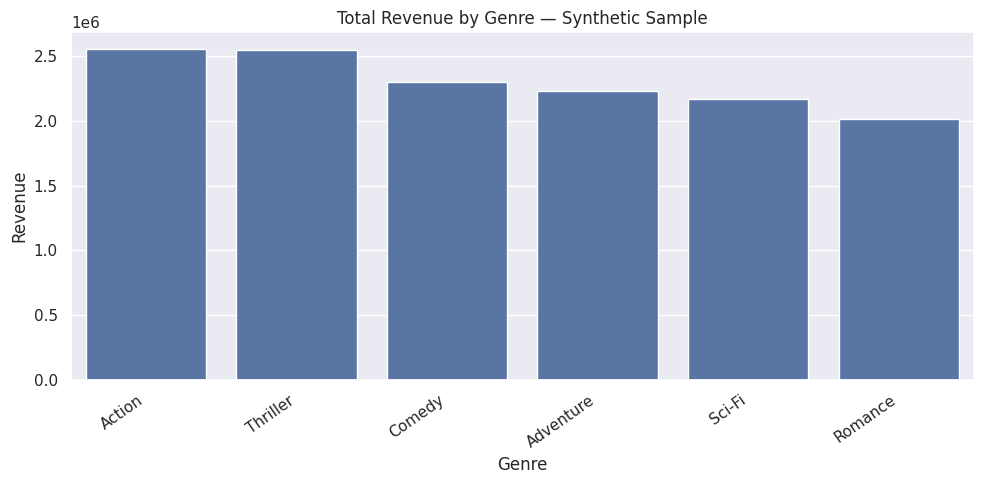

In [9]:
genre_summary = (
    analysis.groupby("genre", dropna=False)
    .agg(shows=("show_id", "nunique"), tickets=("tickets", "sum"),
         revenue=("revenue", "sum"), mean_occupancy_pct=("occupancy_pct", "mean"))
    .sort_values("revenue", ascending=False)
    .reset_index()
)
display(genre_summary)

plt.figure(figsize=(10, 5))
sns.barplot(data=genre_summary, x="genre", y="revenue")
plt.title("Total Revenue by Genre — Synthetic Sample")
plt.xlabel("Genre")
plt.ylabel("Revenue")
plt.xticks(rotation=35, ha="right")
plt.tight_layout()
plt.show()


## 9. Business question 2 — Which show times have higher occupancy?

,show_hour,shows,tickets,revenue,mean_occupancy_pct
0,10.0,247,12451,2195052,52.650810
1,13.0,262,15636,2745823,61.687341
2,16.0,255,15622,2746620,63.668192
3,19.0,238,16952,3030220,73.574463
4,22.0,246,17371,3092816,72.454720


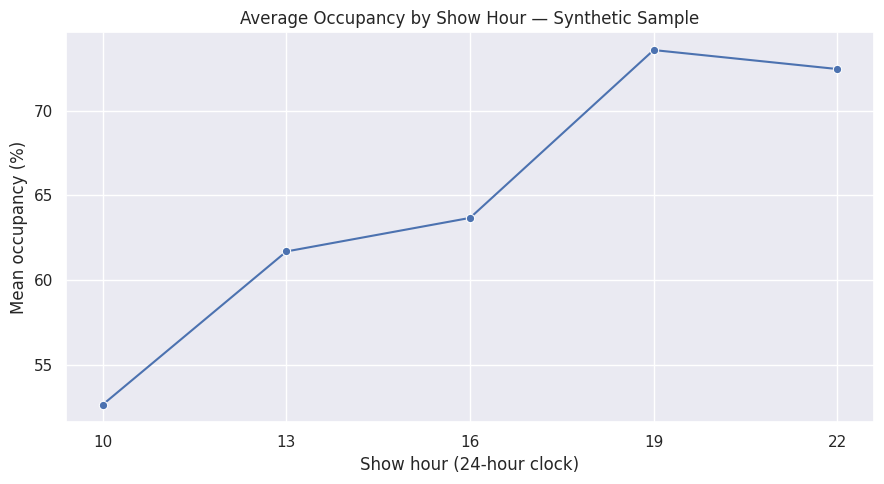

In [10]:
showtime_summary = (
    analysis.dropna(subset=["show_hour"])
    .groupby("show_hour")
    .agg(shows=("show_id", "nunique"), tickets=("tickets", "sum"),
         revenue=("revenue", "sum"), mean_occupancy_pct=("occupancy_pct", "mean"))
    .reset_index()
    .sort_values("show_hour")
)
display(showtime_summary)

plt.figure(figsize=(9, 5))
sns.lineplot(data=showtime_summary, x="show_hour", y="mean_occupancy_pct", marker="o")
plt.title("Average Occupancy by Show Hour — Synthetic Sample")
plt.xlabel("Show hour (24-hour clock)")
plt.ylabel("Mean occupancy (%)")
plt.xticks(showtime_summary["show_hour"])
plt.tight_layout()
plt.show()


## 10. Business question 3 — How do weekends differ?

,is_weekend_label,shows,tickets,revenue,mean_occupancy_pct,revenue_per_ticket
0,Weekday,896,52711,9341800,60.753689,175.820312
1,Weekend,353,25421,4483731,74.744570,176.073654


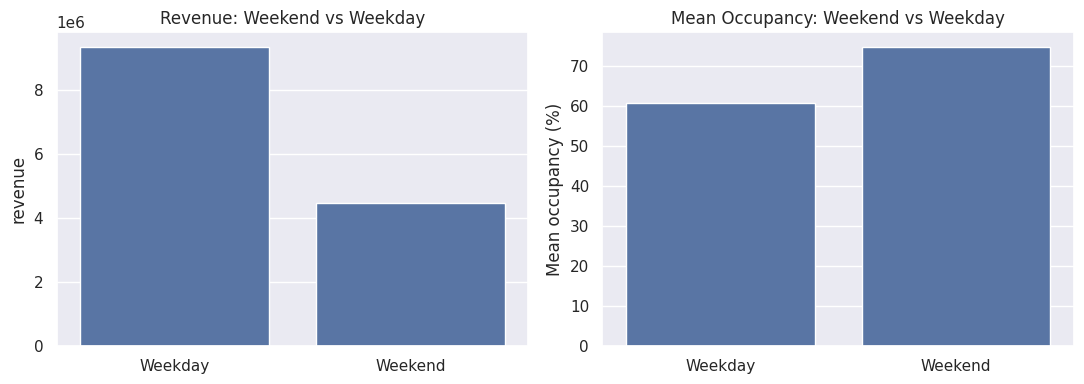

In [11]:
weekend_summary = (
    analysis.groupby("is_weekend_label")
    .agg(shows=("show_id", "nunique"), tickets=("tickets", "sum"),
         revenue=("revenue", "sum"), mean_occupancy_pct=("occupancy_pct", "mean"),
         revenue_per_ticket=("revenue_per_ticket", "mean"))
    .reset_index()
)
display(weekend_summary)

fig, axes = plt.subplots(1, 2, figsize=(11, 4))
sns.barplot(data=weekend_summary, x="is_weekend_label", y="revenue", ax=axes[0])
axes[0].set_title("Revenue: Weekend vs Weekday")
axes[0].set_xlabel("")
sns.barplot(data=weekend_summary, x="is_weekend_label", y="mean_occupancy_pct", ax=axes[1])
axes[1].set_title("Mean Occupancy: Weekend vs Weekday")
axes[1].set_xlabel("")
axes[1].set_ylabel("Mean occupancy (%)")
plt.tight_layout()
plt.show()


## 11. Business question 4 — Which cinemas perform best?

,cinema,city,shows,tickets,revenue,mean_occupancy_pct
0,SS_Coimbatore,Coimbatore,619,41122,7272893,63.968318
1,SS_Tiruppur,Tiruppur,314,20155,3615966,64.187898
2,SS_Erode,Erode,316,16855,2936672,66.673259


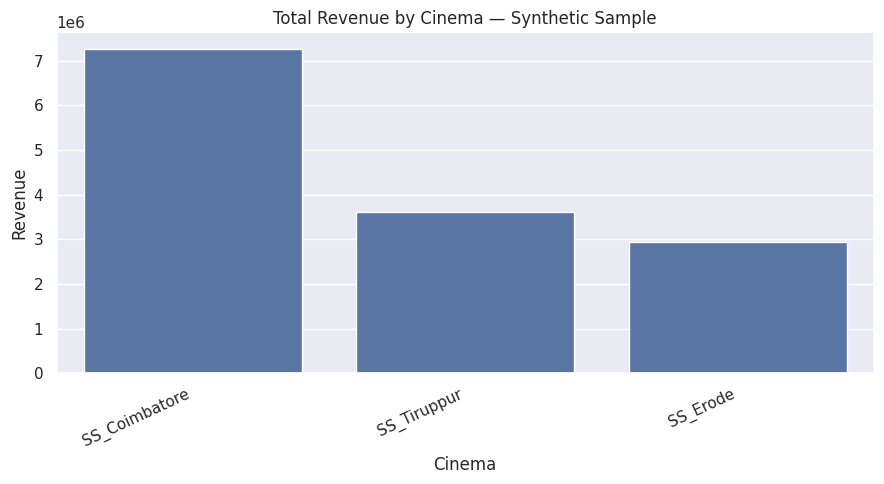

In [13]:

# Cinema performance analysis — corrected

# Add city information from cinemas.csv if it is missing
if "city" not in analysis.columns:
    city_lookup = cinemas[["cinema", "city"]].drop_duplicates()
    analysis = analysis.merge(
        city_lookup,
        on="cinema",
        how="left",
        validate="many_to_one"
    )

# Check required columns
required_cols = [
    "cinema", "city", "show_id",
    "tickets", "revenue", "occupancy_pct"
]

missing_cols = [col for col in required_cols if col not in analysis.columns]

if missing_cols:
    raise ValueError(f"Missing columns in analysis: {missing_cols}")

# Summarize cinema performance
cinema_summary = (
    analysis.groupby(["cinema", "city"], dropna=False)
    .agg(
        shows=("show_id", "nunique"),
        tickets=("tickets", "sum"),
        revenue=("revenue", "sum"),
        mean_occupancy_pct=("occupancy_pct", "mean")
    )
    .sort_values("revenue", ascending=False)
    .reset_index()
)

display(cinema_summary)

# Visualize total revenue by cinema
plt.figure(figsize=(9, 5))
sns.barplot(data=cinema_summary, x="cinema", y="revenue")
plt.title("Total Revenue by Cinema — Synthetic Sample")
plt.xlabel("Cinema")
plt.ylabel("Revenue")
plt.xticks(rotation=25, ha="right")
plt.tight_layout()
plt.show()


## 12. Business question 5 — How do offers relate to bookings and revenue?

,offer,shows,tickets,revenue,mean_occupancy_pct,revenue_per_ticket
0,No Offer,942,59001,11029310,64.661182,185.509554
1,Student 15%,99,6226,944372,65.330247,151.737374
2,Student 20%,114,6990,939760,63.533626,135.298246
3,App 15%,94,5915,912089,65.944444,154.180851


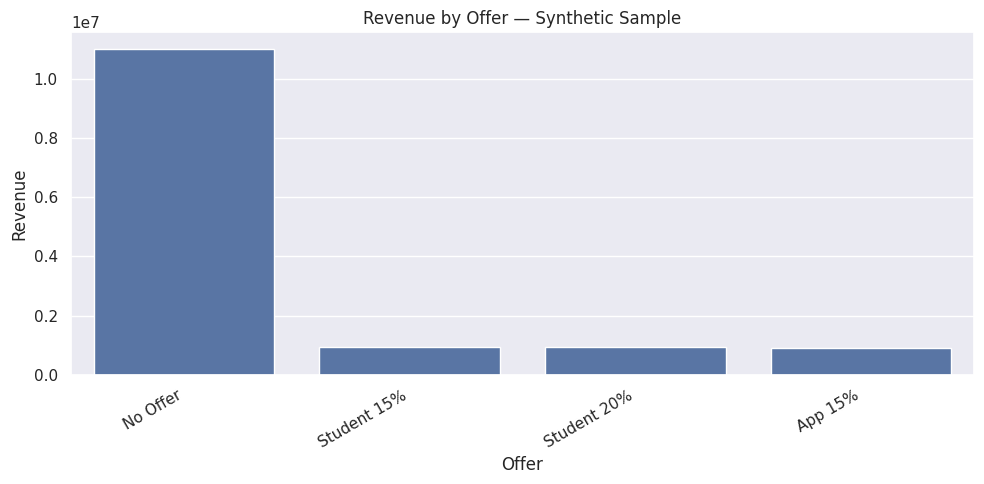

Interpretation caution: offers may be targeted to specific seat classes, audiences or dates.
This grouped comparison is descriptive and does not establish causal impact.


In [14]:
offer_summary = (
    analysis.groupby("offer", dropna=False)
    .agg(shows=("show_id", "nunique"), tickets=("tickets", "sum"),
         revenue=("revenue", "sum"), mean_occupancy_pct=("occupancy_pct", "mean"),
         revenue_per_ticket=("revenue_per_ticket", "mean"))
    .sort_values("revenue", ascending=False)
    .reset_index()
)
display(offer_summary)

plt.figure(figsize=(10, 5))
sns.barplot(data=offer_summary, x="offer", y="revenue")
plt.title("Revenue by Offer — Synthetic Sample")
plt.xlabel("Offer")
plt.ylabel("Revenue")
plt.xticks(rotation=30, ha="right")
plt.tight_layout()
plt.show()

print("Interpretation caution: offers may be targeted to specific seat classes, audiences or dates.")
print("This grouped comparison is descriptive and does not establish causal impact.")


## 13. Business question 6 — How does release week influence demand?

,release_week_group,shows,tickets,revenue,mean_occupancy_pct
0,Week 1,95,6596,1159269,72.349123
1,Week 2,97,6339,1158635,68.569874
2,Weeks 3–4,178,10231,1801336,58.933521
3,Week 5+,273,13340,2337242,49.702890


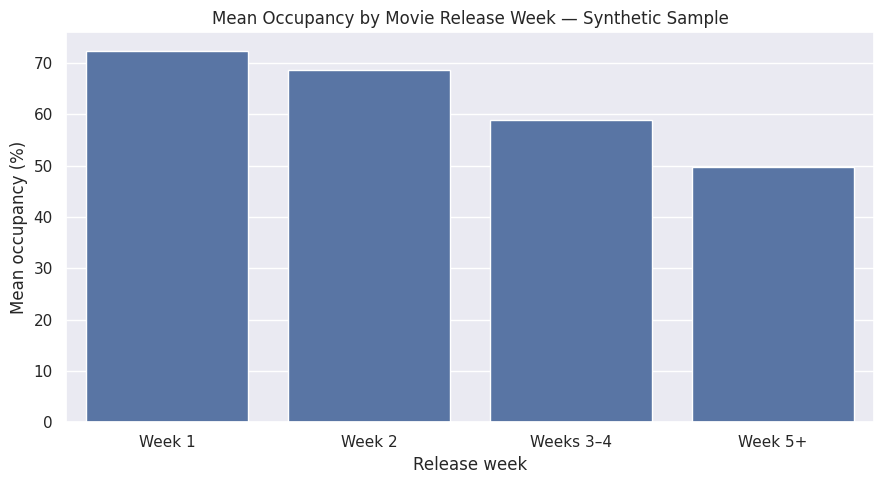

In [15]:
release_summary = (
    analysis.dropna(subset=["release_week_group"])
    .groupby("release_week_group", observed=False)
    .agg(shows=("show_id", "nunique"), tickets=("tickets", "sum"),
         revenue=("revenue", "sum"), mean_occupancy_pct=("occupancy_pct", "mean"))
    .reset_index()
)
display(release_summary)

plt.figure(figsize=(9, 5))
sns.barplot(data=release_summary, x="release_week_group", y="mean_occupancy_pct")
plt.title("Mean Occupancy by Movie Release Week — Synthetic Sample")
plt.xlabel("Release week")
plt.ylabel("Mean occupancy (%)")
plt.tight_layout()
plt.show()


## 14. Additional exploration — relationships and correlations

,tickets,revenue,screen_capacity,ticket_price,runtime,show_hour,release_week,occupancy_pct,revenue_per_ticket
tickets,1.000000,0.755934,0.343838,0.065660,0.069774,0.315066,-0.298817,0.903961,0.053283
revenue,0.755934,1.000000,0.267051,0.659082,0.072357,0.241022,-0.233512,0.680304,0.657670
screen_capacity,0.343838,0.267051,1.000000,0.009113,0.032344,0.021193,0.076627,-0.065129,0.032328
ticket_price,0.065660,0.659082,0.009113,1.000000,0.015300,0.026950,-0.027339,0.067880,0.988583
runtime,0.069774,0.072357,0.032344,0.015300,1.000000,-0.011651,0.008563,0.066370,0.024693
show_hour,0.315066,0.241022,0.021193,0.026950,-0.011651,1.000000,-0.018135,0.326481,0.016580
release_week,-0.298817,-0.233512,0.076627,-0.027339,0.008563,-0.018135,1.000000,-0.351864,-0.029818
occupancy_pct,0.903961,0.680304,-0.065129,0.067880,0.066370,0.326481,-0.351864,1.000000,0.045742
revenue_per_ticket,0.053283,0.657670,0.032328,0.988583,0.024693,0.016580,-0.029818,0.045742,1.000000


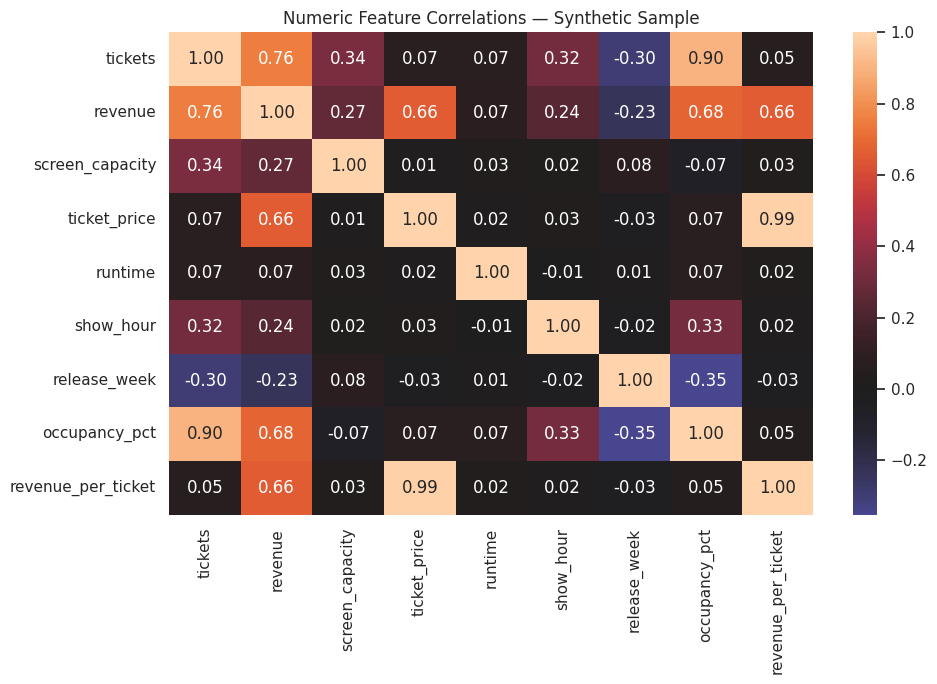

In [16]:
numeric_cols = ["tickets", "revenue", "screen_capacity", "ticket_price",
                "runtime", "show_hour", "release_week", "occupancy_pct", "revenue_per_ticket"]
corr = analysis[numeric_cols].corr(numeric_only=True)
display(corr)

plt.figure(figsize=(10, 7))
sns.heatmap(corr, annot=True, fmt=".2f", center=0)
plt.title("Numeric Feature Correlations — Synthetic Sample")
plt.tight_layout()
plt.show()


## 15. Feature engineering and feature selection

Features created:
- `show_hour`: hour extracted from show time.
- `is_weekend`: boolean weekend indicator.
- `is_weekend_label`: readable weekday/weekend category.
- `release_week` and `release_week_group`: time since release, where release date is known.
- `revenue_per_ticket`: revenue divided by tickets sold.
- `occupancy_rate` / `occupancy_pct`: tickets divided by screen capacity.
- `holiday`: calendar flag.

Feature selection guidance:
- For descriptive analysis, retain relevant business dimensions even if correlated.
- For predictive modeling, define the target first and avoid leakage. For example, if predicting revenue, do not use `revenue_per_ticket` if it is computed from revenue itself, or any future information unavailable at prediction time.
- Remove identifiers from model features unless there is a justified use.
- Use one-hot encoding for nominal categories and a time-based validation split for any future forecasting.


In [17]:
# Candidate feature table for downstream analysis/modeling.
candidate_features = [
    "genre", "language", "runtime", "certification", "cinema", "city", "screen",
    "show_hour", "seat_class", "offer", "weekday", "holiday", "is_weekend",
    "release_week", "release_week_group", "screen_capacity", "ticket_price",
    "tickets", "revenue", "occupancy_rate", "revenue_per_ticket"
]
feature_table = analysis[[c for c in candidate_features if c in analysis.columns]].copy()

# Example encoding for an exploratory modeling matrix only.
categorical_cols = [c for c in [
    "genre", "language", "certification", "cinema", "city", "seat_class",
    "offer", "weekday", "release_week_group"
] if c in feature_table.columns]
encoded_features = pd.get_dummies(
    feature_table.drop(columns=["revenue", "revenue_per_ticket"], errors="ignore"),
    columns=categorical_cols,
    dummy_na=True,
    dtype=int
)
print("Feature table shape:", feature_table.shape)
print("Encoded exploratory feature matrix shape:", encoded_features.shape)
display(feature_table.head())


Feature table shape: (1249, 21)
Encoded exploratory feature matrix shape: (1249, 54)


,genre,language,runtime,certification,cinema,city,screen,show_hour,seat_class,offer,weekday,holiday,is_weekend,release_week,release_week_group,screen_capacity,ticket_price,tickets,revenue,occupancy_rate,revenue_per_ticket
0,Thriller,Tamil,131,A,SS_Coimbatore,Coimbatore,2,13.0,Standard,Student 20%,Thursday,True,False,NaN,NaN,90.0,120.0,63,6048,0.700000,96.0
1,Sci-Fi,English,142,UA,SS_Coimbatore,Coimbatore,2,16.0,Standard,No Offer,Thursday,True,False,NaN,NaN,90.0,150.0,52,7800,0.577778,150.0
2,Romance,Tamil,128,U,SS_Coimbatore,Coimbatore,2,22.0,Premium,Student 20%,Thursday,True,False,NaN,NaN,90.0,NaN,25,4400,0.277778,176.0
3,Adventure,Tamil,124,U,SS_Tiruppur,Tiruppur,1,10.0,Premium,No Offer,Thursday,True,False,NaN,NaN,100.0,220.0,62,13640,0.620000,220.0
4,Action,English,135,UA,SS_Tiruppur,Tiruppur,1,13.0,Standard,Student 20%,Thursday,True,False,NaN,NaN,100.0,120.0,33,3168,0.330000,96.0


## 16. Export deliverables

In [19]:
# Keep the audit trail and the clean analysis output.
quality_summary.to_csv("data_quality_summary.csv", index=False)
analysis.to_csv("cinema_cleaned_analysis.csv", index=False)
genre_summary.to_csv("genre_revenue_summary.csv", index=False)
showtime_summary.to_csv("showtime_occupancy_summary.csv", index=False)
weekend_summary.to_csv("weekend_comparison_summary.csv", index=False)
cinema_summary.to_csv("cinema_performance_summary.csv", index=False)
offer_summary.to_csv("offer_analysis_summary.csv", index=False)
release_summary.to_csv("release_week_summary.csv", index=False)
feature_table.to_csv("cinema_feature_table.csv", index=False)
encoded_features.to_csv("cinema_encoded_features.csv", index=False)

print("Exported cleaned dataset, quality summary, business summaries and feature tables.")


Exported cleaned dataset, quality summary, business summaries and feature tables.


In [21]:
from google.colab import files

files.download("cinema_cleaned_analysis.csv")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>